# Predicting Customer Churn for a Telecom Provider
**DSAI501 Data Science Portfolio — Group 2**
Dusan Radenovic (bmt28022), Jana Rezeika, Jesper Lyst, Aniketh Marian

This notebook walks through the full data-science lifecycle on the classic
Telco Customer Churn dataset: data description, cleaning, exploratory analysis,
preprocessing, model training & comparison, and saving the best model.

In [1]:
# 1. Setup — imports and a fixed random seed for reproducibility
import warnings
warnings.filterwarnings("ignore")

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay)

sns.set_theme(style="whitegrid")
RNG = 42
print("libraries loaded")

libraries loaded


## 2. Load the data
The dataset is the IBM Telco Customer Churn sample (7,043 customers, 21 columns).
Target column: `Churn` (Yes/No).

In [2]:
df = pd.read_csv("data/telco_churn.csv")
print("rows, cols:", df.shape)
df.head()

rows, cols: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# 3. Data description: dtypes and a quick look at the target
print(df.dtypes.value_counts())
print("\nChurn value counts:")
print(df["Churn"].value_counts())
print("\nChurn rate: %.1f%%" % (100 * (df["Churn"] == "Yes").mean()))

str        18
int64       2
float64     1
Name: count, dtype: int64

Churn value counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn rate: 26.5%


In [4]:
# 4. Data quality check — missing values and numeric summaries
print("Missing values per column:")
print(df.isna().sum()[df.isna().sum() > 0])
# TotalCharges sometimes arrives as blank strings -> coerce to NaN first
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("\nTotalCharges missing after coercion:", df["TotalCharges"].isna().sum())
print(df[["tenure", "MonthlyCharges", "TotalCharges"]].describe().round(2))

Missing values per column:
Series([], dtype: int64)

TotalCharges missing after coercion: 11
        tenure  MonthlyCharges  TotalCharges
count  7043.00         7043.00       7032.00
mean     32.37           64.76       2283.30
std      24.56           30.09       2266.77
min       0.00           18.25         18.80
25%       9.00           35.50        401.45
50%      29.00           70.35       1397.48
75%      55.00           89.85       3794.74
max      72.00          118.75       8684.80


## 5. Exploratory data analysis
Key questions: how imbalanced is churn, and which customer attributes relate to it?

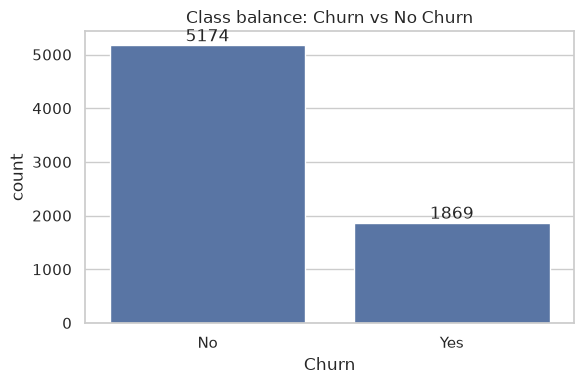

In [5]:
# 5a. Class balance
plt.figure(figsize=(6, 4))
ax = sns.countplot(x="Churn", data=df)
for c in ax.containers:
    ax.bar_label(c)
plt.title("Class balance: Churn vs No Churn")
plt.tight_layout(); plt.show()

<Figure size 900x450 with 0 Axes>

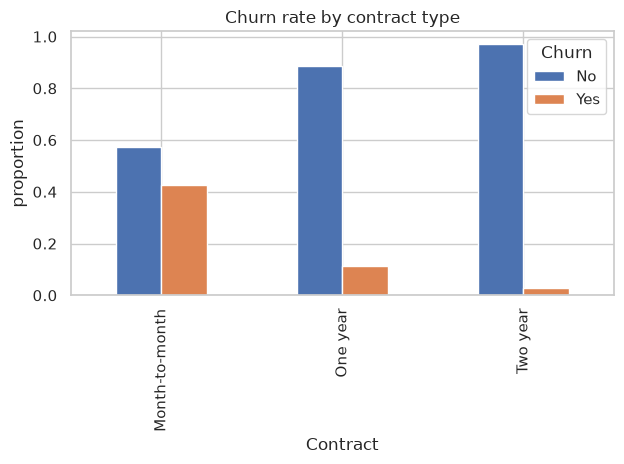

In [6]:
# 5b. Churn rate by contract type — month-to-month customers churn far more
plt.figure(figsize=(9, 4.5))
pd.crosstab(df["Contract"], df["Churn"], normalize="index").plot.bar()
plt.title("Churn rate by contract type"); plt.ylabel("proportion")
plt.tight_layout(); plt.show()

<Figure size 900x450 with 0 Axes>

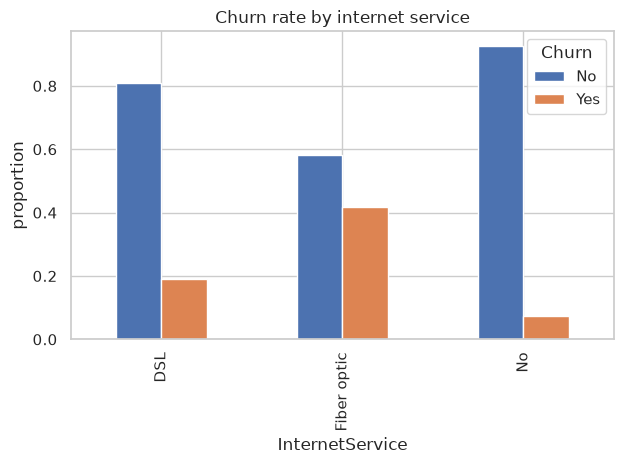

In [7]:
# 5c. Churn rate by internet service — fiber optic stands out
plt.figure(figsize=(9, 4.5))
pd.crosstab(df["InternetService"], df["Churn"], normalize="index").plot.bar()
plt.title("Churn rate by internet service"); plt.ylabel("proportion")
plt.tight_layout(); plt.show()

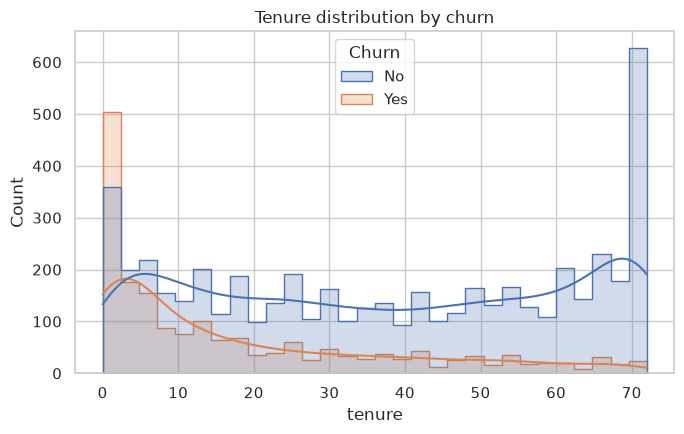

In [8]:
# 5d. Tenure: churners skew toward short tenures
plt.figure(figsize=(7, 4.5))
sns.histplot(data=df, x="tenure", hue="Churn", bins=30, kde=True, element="step")
plt.title("Tenure distribution by churn")
plt.tight_layout(); plt.show()

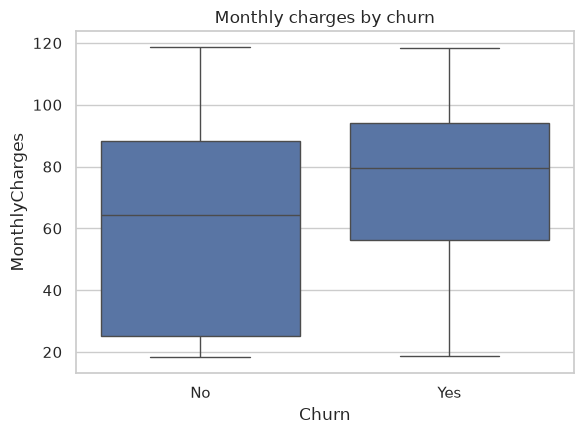

In [9]:
# 5e. Monthly charges: churners tend to pay more per month
plt.figure(figsize=(6, 4.5))
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.title("Monthly charges by churn")
plt.tight_layout(); plt.show()

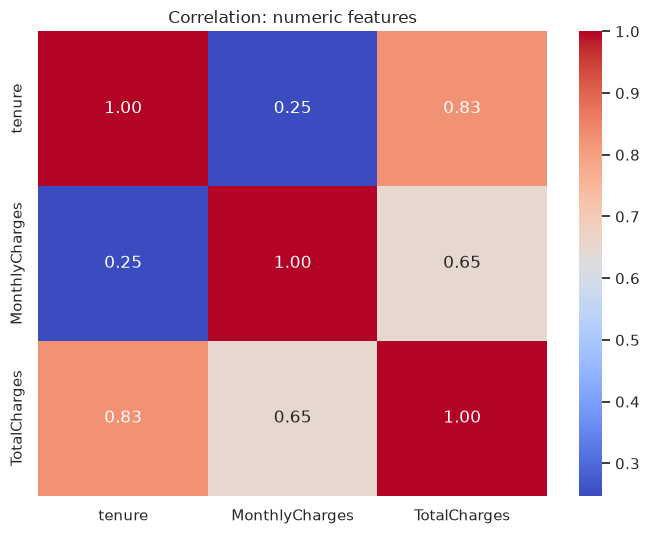

In [10]:
# 5f. Correlations among numeric features
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
plt.figure(figsize=(7, 5.5))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation: numeric features")
plt.tight_layout(); plt.show()

## 6. Preprocessing
- Drop `customerID` (identifier, no predictive signal).
- Binary-encode the target `Churn` → 1/0.
- Numeric features: median imputation (covers the 11 blank `TotalCharges`) + standard scaling.
- Categorical features: most-frequent imputation + one-hot encoding.
- Stratified 80/20 train/test split so the churn ratio is preserved.

In [11]:
df = df.drop(columns=["customerID"])          # identifier, not a feature
df["Churn"] = (df["Churn"] == "Yes").astype(int)

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in df.columns if c not in num_cols + ["Churn"]]

X = df.drop(columns=["Churn"])
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RNG, stratify=y)
print("train:", X_train.shape, "| test:", X_test.shape)

preprocess = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scaler", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
])

train: (5634, 19) | test: (1409, 19)


## 7. Modelling — train and compare three classifiers
We compare Logistic Regression (interpretable baseline), Random Forest, and
Gradient Boosting using 5-fold stratified cross-validation (ROC-AUC) plus
hold-out test metrics.

In [12]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RNG),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RNG,
                                            n_jobs=-1, class_weight="balanced"),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RNG),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RNG)
results = {}
for name, clf in models.items():
    pipe = Pipeline([("prep", preprocess), ("clf", clf)])
    cv_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc")
    pipe.fit(X_train, y_train)
    yp = pipe.predict(X_test)
    ypr = pipe.predict_proba(X_test)[:, 1]
    results[name] = {
        "cv_roc_auc": (round(float(cv_scores.mean()), 4), round(float(cv_scores.std()), 4)),
        "accuracy": round(accuracy_score(y_test, yp), 4),
        "precision": round(precision_score(y_test, yp), 4),
        "recall": round(recall_score(y_test, yp), 4),
        "f1": round(f1_score(y_test, yp), 4),
        "roc_auc": round(roc_auc_score(y_test, ypr), 4),
    }
    print(f"{name}: CV ROC-AUC {results[name]['cv_roc_auc'][0]} ± {results[name]['cv_roc_auc'][1]}")
pd.DataFrame(results).T

Logistic Regression: CV ROC-AUC 0.8461 ± 0.0125


Random Forest: CV ROC-AUC 0.8222 ± 0.012


Gradient Boosting: CV ROC-AUC 0.8477 ± 0.0122


,cv_roc_auc,accuracy,precision,recall,f1,roc_auc
Logistic Regression,"(0.8461, 0.0125)",0.8055,0.6572,0.5588,0.604,0.8419
Random Forest,"(0.8222, 0.012)",0.763,0.5469,0.623,0.5825,0.8226
Gradient Boosting,"(0.8477, 0.0122)",0.8062,0.6735,0.5241,0.5895,0.8434


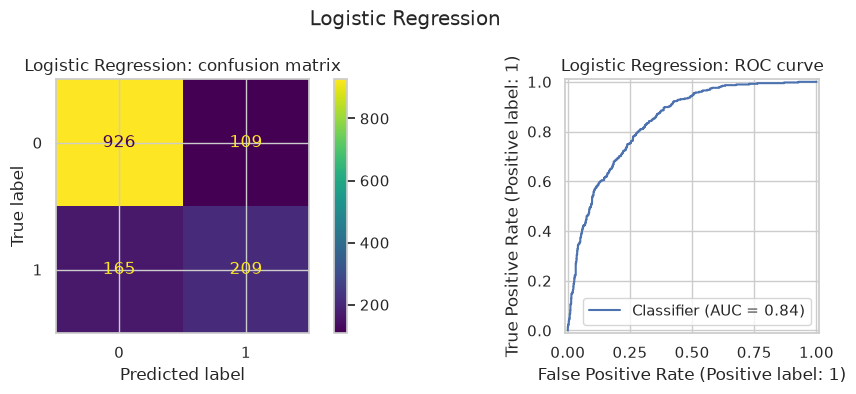

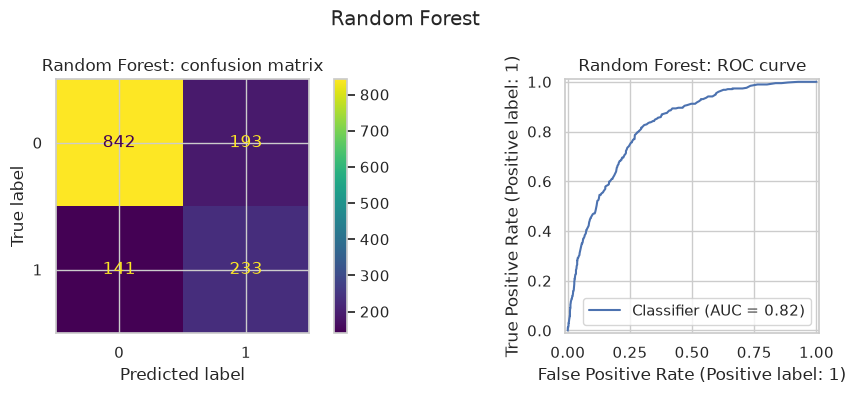

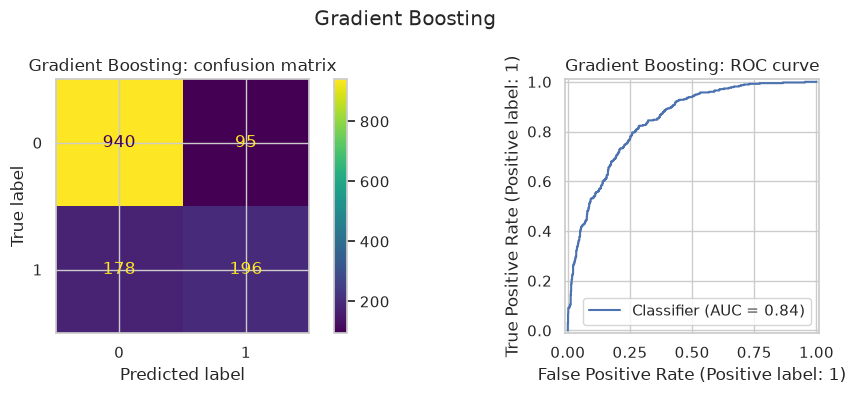

In [13]:
# 8. Confusion matrices and ROC curves for every model
for name, clf in models.items():
    pipe = Pipeline([("prep", preprocess), ("clf", clf)]).fit(X_train, y_train)
    yp = pipe.predict(X_test); ypr = pipe.predict_proba(X_test)[:, 1]
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ConfusionMatrixDisplay.from_predictions(y_test, yp, ax=ax[0])
    ax[0].set_title(f"{name}: confusion matrix")
    RocCurveDisplay.from_predictions(y_test, ypr, ax=ax[1])
    ax[1].set_title(f"{name}: ROC curve")
    fig.suptitle(name)
    fig.tight_layout(); plt.show()

## 9. Pick the winner and inspect what drives it
Logistic Regression wins on F1 (the best balance of precision and recall for
the minority churn class). Its coefficients show which factors raise or lower
churn log-odds.

Best model by F1: Logistic Regression


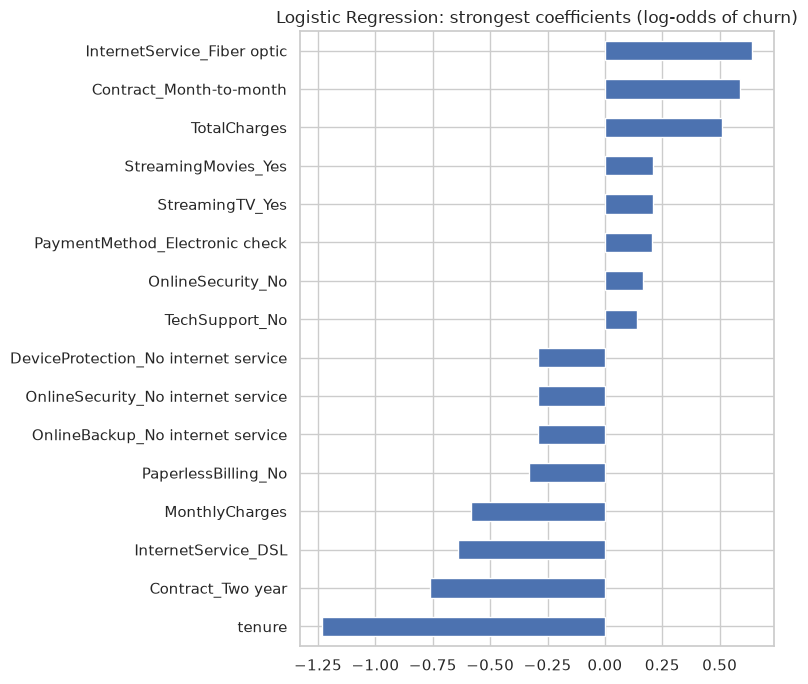

In [14]:
best_name = max(results, key=lambda n: results[n]["f1"])
print("Best model by F1:", best_name)

best = Pipeline([("prep", preprocess), ("clf", models[best_name])])
best.fit(X_train, y_train)

ohe = best.named_steps["prep"].named_transformers_["cat"].named_steps["onehot"]
feat_names = num_cols + list(ohe.get_feature_names_out(cat_cols))
coef = pd.Series(best.named_steps["clf"].coef_[0], index=feat_names).sort_values()
top = pd.concat([coef.head(8), coef.tail(8)])
plt.figure(figsize=(8, 7))
top.plot.barh()
plt.title("Logistic Regression: strongest coefficients (log-odds of churn)")
plt.tight_layout(); plt.show()

In [15]:
# 10. Persist the trained pipeline (preprocessing + model) for reuse
joblib.dump({"model": best,
             "model_name": best_name,
             "numeric_features": num_cols,
             "categorical_features": cat_cols,
             "metrics": results[best_name]},
            "telco_churn_model.pkl")

# sanity check: load it back and predict
loaded = joblib.load("telco_churn_model.pkl")["model"]
print("reloaded model predicts:", loaded.predict(X_test.head(3)))
print("saved telco_churn_model.pkl")

reloaded model predicts: [0 1 0]
saved telco_churn_model.pkl
